# Bloque C - C2: Normalización de la tinción

**Objetivo:** decidir si conviene **normalizar el color** de las imágenes antes de aplicar los umbrales de C1.

**Por qué puede hacer falta:** la intensidad de la tinción Giemsa, la iluminación del microscopio y la cámara cambian de un preparado a otro. Si una imagen sale "más clara" o "más azulada", un umbral fijo como `G_p5 < 134` puede fallar aunque las células sean iguales. Esto importa sobre todo para **test**, que son **otros pacientes**.

En C1 vimos que el **fondo** varía poco entre imágenes de train (menos de ~10 niveles). Acá vamos a ver:
1. Si dos métodos simples de normalización reducen esa variación, también **dentro de las células**.
2. Si un umbral elegido con algunos pacientes **funciona mejor en un paciente nuevo** cuando las imágenes están normalizadas (validación *leave-one-patient-out*).

**Métodos que comparamos:**
- **Original:** sin normalizar.
- **Fondo (balance de blancos):** se escala cada canal R, G, B para que el fondo de la imagen quede del mismo color en todas.
- **Reinhard:** se igualan la media y el desvío de cada canal Lab de la imagen a los de una referencia (Reinhard et al., 2001).

**Regla del proyecto:** todo se ajusta **solo con train**. La normalización en sí **no usa el GT** (solo la imagen), así que después se puede aplicar igual a test.

In [1]:
# BLOQUE C - C2: Normalización de la tinción
# Objetivo: ver si normalizar el color de cada imagen hace que los umbrales de C1
# se trasladen mejor de un paciente a otro.

import sys
sys.path.append("..")  # el notebook está en color_stain/, subimos un nivel para poder importar common/

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

from common.config import SEED, LABEL_PARASITIZED, LABEL_UNINFECTED, LABEL_WBC
from common.io_utils import cargar_subset, cargar_imagen, cargar_gt
from segmentation.preprocess import mascara_circular

# Generador de números aleatorios con semilla fija, para que los resultados se puedan repetir
rng = np.random.default_rng(SEED)

FONDO = "Fondo"
CLASES = [FONDO, LABEL_UNINFECTED, LABEL_PARASITIZED, LABEL_WBC]
CODIGO = {FONDO: 0, LABEL_UNINFECTED: 1, LABEL_PARASITIZED: 2, LABEL_WBC: 3}

# Canales que resultaron útiles en C1: G (RGB) y L, a, b (Lab)
CANALES = ["G", "L", "a", "b"]

METODOS = ["Original", "Fondo", "Reinhard"]

## 1. Los dos métodos de normalización

**Fondo (balance de blancos).** El fondo (plasma) casi no toma colorante, así que su color depende sobre todo de la **luz del microscopio y la cámara**. Si lo llevamos a un mismo color en todas las imágenes, corregimos esas diferencias sin tocar lo que es propio de las células.
1. Estimamos el fondo **sin el GT**: dentro del campo circular, los píxeles con G mayor al umbral de **Otsu** (lo mismo que hace el Bloque A para segmentar).
2. Calculamos la mediana R, G, B de ese fondo.
3. Multiplicamos cada canal por `referencia / mediana_de_la_imagen`.

**Reinhard.** Pasamos la imagen a Lab y, para cada canal, restamos la media de la imagen, dividimos por su desvío y aplicamos la media y el desvío de la referencia:

`canal_normalizado = (canal − media_imagen) / desvío_imagen · desvío_ref + media_ref`

Corrige también diferencias en la **intensidad de la tinción**, no solo en la luz. La contra es que la media y el desvío dependen de **qué hay en la imagen**: una imagen con muchas células parasitadas o glóbulos blancos tiene otra media, y Reinhard la "corrige" aunque la tinción sea la misma.

**Referencia:** en los dos casos usamos el **promedio de las 12 imágenes de train**.

In [2]:
def estimar_fondo(imagen_rgb, campo):
    # Máscara del fondo sin usar el GT: píxeles del campo con G por encima del umbral de Otsu
    verde = imagen_rgb[:, :, 1]
    umbral, _ = cv2.threshold(verde[campo].reshape(-1, 1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return campo & (verde > umbral)


def estadisticas_color(imagen_rgb, campo):
    # Lo que necesita cada método: media y desvío Lab del campo, y mediana RGB del fondo
    lab = cv2.cvtColor(imagen_rgb, cv2.COLOR_RGB2LAB)[campo].astype(float)
    fondo = imagen_rgb[estimar_fondo(imagen_rgb, campo)].astype(float)
    return {
        "lab_media": lab.mean(axis=0),
        "lab_desvio": lab.std(axis=0),
        "fondo_rgb": np.median(fondo, axis=0),
    }


def normalizar_fondo(imagen_rgb, est, ref):
    ganancia = ref["fondo_rgb"] / est["fondo_rgb"]  # un factor por canal R, G, B
    return np.clip(imagen_rgb * ganancia, 0, 255).astype(np.uint8)


def normalizar_reinhard(imagen_rgb, est, ref):
    lab = cv2.cvtColor(imagen_rgb, cv2.COLOR_RGB2LAB).astype(np.float32)
    lab = (lab - est["lab_media"]) / est["lab_desvio"] * ref["lab_desvio"] + ref["lab_media"]
    return cv2.cvtColor(np.clip(lab, 0, 255).astype(np.uint8), cv2.COLOR_LAB2RGB)


def normalizar(imagen_rgb, metodo, est, ref):
    if metodo == "Fondo":
        return normalizar_fondo(imagen_rgb, est, ref)
    if metodo == "Reinhard":
        return normalizar_reinhard(imagen_rgb, est, ref)
    return imagen_rgb


def calcular_canales(imagen_rgb):
    # Devuelve una matriz (alto, ancho, 4) con G, L, a, b
    lab = cv2.cvtColor(imagen_rgb, cv2.COLOR_RGB2LAB)
    return np.dstack([imagen_rgb[:, :, 1], lab])


def kernel_circular(radio):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * radio + 1, 2 * radio + 1))

In [3]:
# Estadísticas de color de cada imagen de train (no usan el GT)
imagenes = cargar_subset("train")
estadisticas = {}
for reg in imagenes:
    img = cargar_imagen(reg["patient_id"], reg["image_id"])
    estadisticas[reg["image_id"]] = estadisticas_color(img, mascara_circular(img))

# Referencia = promedio de train
referencia = {k: np.mean([e[k] for e in estadisticas.values()], axis=0) for k in ["lab_media", "lab_desvio", "fondo_rgb"]}

tabla_est = pd.DataFrame({
    iid: {**{f"fondo_{c}": v for c, v in zip("RGB", e["fondo_rgb"])},
          **{f"media_{c}": v for c, v in zip("Lab", e["lab_media"])},
          **{f"desvío_{c}": v for c, v in zip("Lab", e["lab_desvio"])}}
    for iid, e in estadisticas.items()
}).T
tabla_est.loc["REFERENCIA"] = tabla_est.mean()
tabla_est.round(1)

,fondo_R,fondo_G,fondo_B,media_L,media_a,media_b,desvío_L,desvío_a,desvío_b
IMG_20150819_115417.jpg,222.0,180.0,165.0,186.7,143.1,138.1,13.5,3.8,4.8
IMG_20150819_121456.jpg,222.0,181.0,168.0,185.2,142.7,137.3,12.2,3.4,4.0
IMG_20150819_133350.jpg,224.0,183.0,170.0,185.5,144.9,135.7,17.9,6.1,6.6
IMG_20150819_133447.jpg,222.0,179.0,170.0,182.2,146.1,134.1,18.9,7.2,6.6
IMG_20150813_131330.jpg,215.0,183.0,162.0,190.4,137.4,141.4,15.1,4.2,4.3
IMG_20150813_130332.jpg,218.0,184.0,163.0,191.4,138.9,142.1,15.3,4.9,4.7
IMG_20150813_162016.jpg,224.0,181.0,172.0,186.7,145.1,135.4,10.8,3.8,3.2
IMG_20150813_163120.jpg,221.0,179.0,170.0,187.2,143.8,136.7,10.8,3.3,3.0
IMG_20150930_161825.jpg,221.0,177.0,160.0,183.2,144.6,140.4,14.7,5.3,3.5
IMG_20150930_162315.jpg,224.0,181.0,166.0,184.9,145.1,138.1,15.1,5.3,4.2


## 2. Cómo se ven las imágenes normalizadas

Tomamos un recorte del centro de una imagen de cada paciente de train y lo mostramos con los tres métodos. Lo que buscamos es que, después de normalizar, los recortes se parezcan más entre sí.

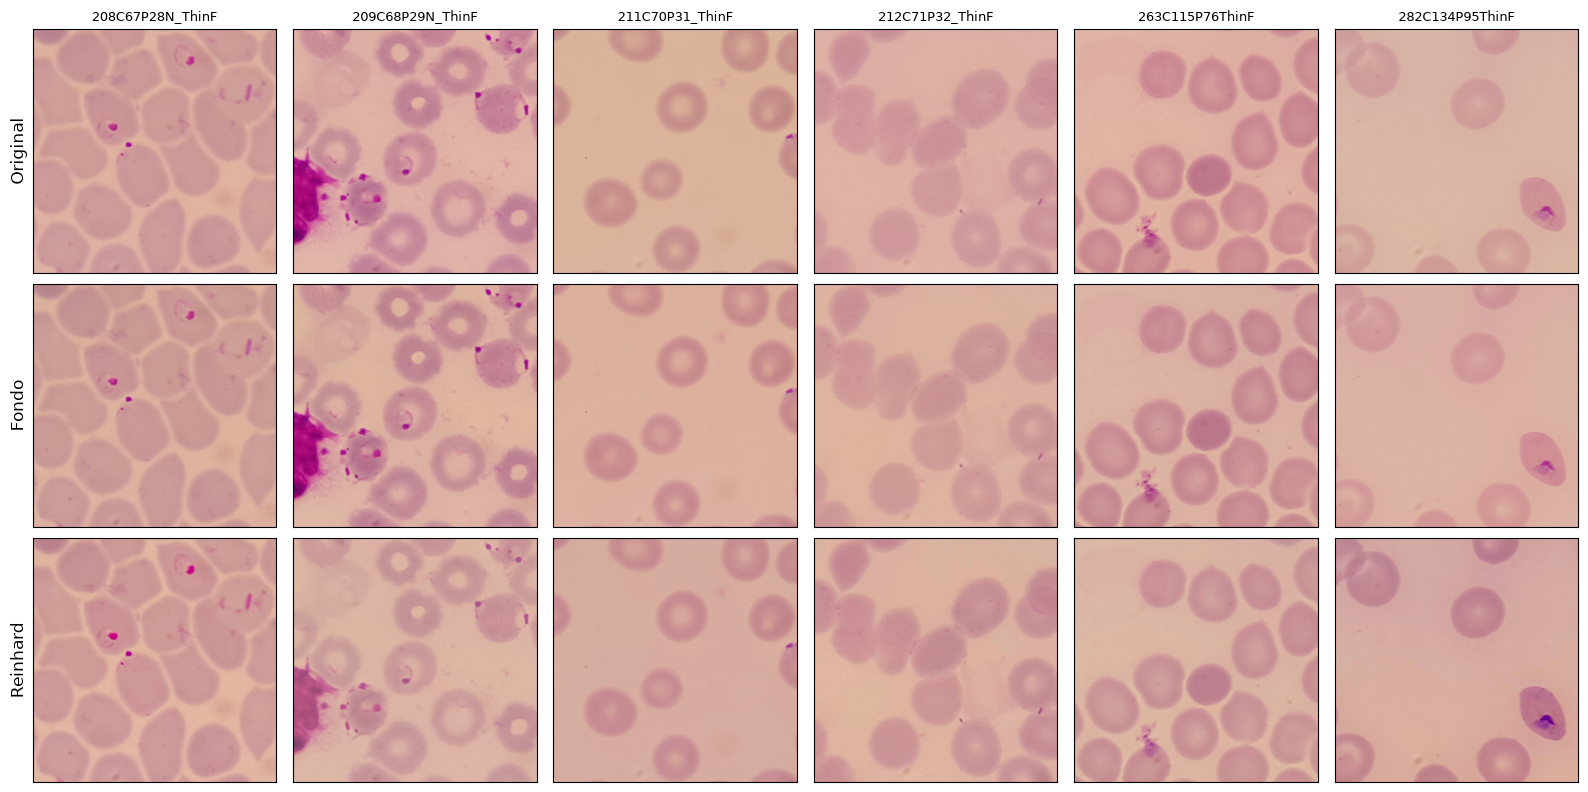

In [4]:
# Una imagen por paciente
una_por_paciente = list({reg["patient_id"]: reg for reg in imagenes}.values())
mitad = 300

fig, ax = plt.subplots(len(METODOS), len(una_por_paciente), figsize=(16, 8))
for col, reg in enumerate(una_por_paciente):
    img = cargar_imagen(reg["patient_id"], reg["image_id"])
    cy, cx = img.shape[0] // 2, img.shape[1] // 2
    est = estadisticas[reg["image_id"]]
    for fila, metodo in enumerate(METODOS):
        # Normalizamos la imagen entera (con sus estadísticas) y después recortamos
        recorte = normalizar(img, metodo, est, referencia)[cy - mitad:cy + mitad, cx - mitad:cx + mitad]
        ax[fila, col].imshow(recorte)
        ax[fila, col].set_xticks([])
        ax[fila, col].set_yticks([])
        if fila == 0:
            ax[fila, col].set_title(reg["patient_id"], fontsize=9)
    for fila, metodo in enumerate(METODOS):
        ax[fila, 0].set_ylabel(metodo, fontsize=12)
plt.tight_layout()
plt.show()

## 3. Base de píxeles y de células para cada método

Repetimos lo de C1, pero ahora **una vez por método**:
- **Píxeles:** de cada imagen y cada clase tomamos hasta `N_POR_CLASE` píxeles al azar. Son **los mismos píxeles** en los tres métodos, así la comparación es justa.
- **Células:** para cada eritrocito del GT calculamos el **percentil 5** de cada canal (los píxeles más oscuros de la célula, que es lo que mejor separaba parasitadas en C1).

In [5]:
N_POR_CLASE = 5000  # píxeles por clase y por imagen

tablas_px = []
filas_celulas = []
for reg in imagenes:
    img = cargar_imagen(reg["patient_id"], reg["image_id"])
    anot, _ = cargar_gt(reg["patient_id"], reg["image_id"])
    campo = mascara_circular(img)
    est = estadisticas[reg["image_id"]]

    # Mapa de clases: -1 = fuera del campo, 0 = fondo, y luego cada polígono pinta su clase
    mapa = np.full(img.shape[:2], -1, dtype=np.int8)
    mapa[campo] = 0
    for clase in [LABEL_UNINFECTED, LABEL_PARASITIZED, LABEL_WBC]:
        for a in anot:
            if a["label"] == clase and a["polygon"] is not None:
                cv2.fillPoly(mapa, [np.round(a["polygon"]).astype(np.int32)], CODIGO[clase])

    # Elegimos los píxeles una sola vez, para usar los mismos en los tres métodos
    elegidos = {}
    for clase, codigo in CODIGO.items():
        filas_px, cols_px = np.nonzero(mapa == codigo)
        if len(filas_px) == 0:
            continue  # por ejemplo, imágenes sin glóbulos blancos
        k = rng.choice(len(filas_px), size=min(N_POR_CLASE, len(filas_px)), replace=False)
        elegidos[clase] = (filas_px[k], cols_px[k])

    for metodo in METODOS:
        canales_img = calcular_canales(normalizar(img, metodo, est, referencia))

        for clase, (filas_px, cols_px) in elegidos.items():
            t = pd.DataFrame(canales_img[filas_px, cols_px].astype(float), columns=CANALES)
            t["clase"] = clase
            t["metodo"] = metodo
            t["image_id"] = reg["image_id"]
            t["patient_id"] = reg["patient_id"]
            tablas_px.append(t)

        # Percentil 5 de cada canal dentro de cada eritrocito
        for a in anot:
            if a["label"] not in [LABEL_UNINFECTED, LABEL_PARASITIZED] or a["polygon"] is None:
                continue
            poly = np.round(a["polygon"]).astype(np.int32)
            x0, y0 = np.maximum(poly.min(axis=0), 0)
            x1, y1 = poly.max(axis=0) + 1
            mascara = np.zeros((y1 - y0, x1 - x0), dtype=np.uint8)
            cv2.fillPoly(mascara, [poly - [x0, y0]], 1)
            valores = canales_img[y0:y1, x0:x1][mascara > 0].astype(float)
            fila = {"metodo": metodo, "patient_id": reg["patient_id"], "label": a["label"]}
            for k, canal in enumerate(CANALES):
                fila[f"{canal}_p5"] = np.percentile(valores[:, k], 5)
            filas_celulas.append(fila)

pixeles = pd.concat(tablas_px, ignore_index=True)
celulas = pd.DataFrame(filas_celulas)

print("Píxeles por clase (cada método):")
print(pixeles[pixeles["metodo"] == "Original"]["clase"].value_counts())
print("\nEritrocitos por clase (cada método):")
print(celulas[celulas["metodo"] == "Original"]["label"].value_counts())

Píxeles por clase (cada método):
clase
Fondo               60000
Uninfected          60000
Parasitized         60000
White_Blood_Cell    25000
Name: count, dtype: int64

Eritrocitos por clase (cada método):
label
Uninfected     2135
Parasitized     217
Name: count, dtype: int64


## 4. ¿Cuánto varía el color entre imágenes?

Para cada imagen calculamos la **mediana** de cada canal en cada clase, y después la **diferencia entre la imagen más alta y la más baja** (en niveles de 0 a 255). Si la normalización funciona, esa diferencia tiene que bajar.

In [6]:
medianas = pixeles.groupby(["metodo", "clase", "image_id"])[CANALES].median()
variacion = medianas.groupby(["metodo", "clase"]).max() - medianas.groupby(["metodo", "clase"]).min()

# Una tabla por canal: filas = clase, columnas = método
variacion = variacion.unstack("metodo").reindex(CLASES)
variacion = variacion.reindex(columns=pd.MultiIndex.from_product([CANALES, METODOS]))
variacion

G                       L                       a  \
                 Original Fondo Reinhard Original Fondo Reinhard Original   
clase                                                                       
Fondo                 8.0   1.0     10.0      5.0   2.0      8.0      6.0   
Uninfected           19.0  14.0     16.0     14.0  13.0     12.0      7.0   
Parasitized          14.0  14.0     24.0     12.0  10.0     18.0      8.0   
White_Blood_Cell     89.0  87.0     97.5     64.0  63.0     75.0     15.5   

                                       b                 
                 Fondo Reinhard Original Fondo Reinhard  
clase                                                    
Fondo              1.0      2.0      5.0   2.0      3.0  
Uninfected         5.0      6.0      7.0   6.0      5.0  
Parasitized        8.0     10.0     11.0   8.0      4.0  
White_Blood_Cell  12.0      9.0     17.0  18.0     30.0

**Qué se ve:**
- **Fondo:** el balance de blancos lo deja prácticamente igual en todas las imágenes (diferencias de 1-2 niveles, contra ~5-8 del original). Es lo esperable, porque es justo lo que corrige.
- **Eritrocitos:** la variación baja poco (en G, de 19 a 14 niveles en sanas y nada en parasitadas). Esto sugiere que **la diferencia entre imágenes no se explica solo por la iluminación**: podría estar asociada principalmente a diferencias de tinción entre preparados (no medimos esas causas por separado).
- **Reinhard** no reduce la variación en G y L de parasitadas y glóbulos blancos; incluso la **aumenta**. Pasa porque la media y el desvío de cada imagen dependen de cuántas células, parásitos y WBC tiene, y al "igualarlos" mueve el color de imágenes que ya estaban bien. En cambio, en **b** (el canal de lo violeta) sí acerca mucho a las parasitadas (de 11 a 4 niveles), aunque separa más a los glóbulos blancos.

## 5. ¿Los umbrales funcionan mejor en un paciente nuevo?

Esta es la pregunta que importa para test. La respondemos **solo con train**, con validación **leave-one-patient-out**:
1. Dejamos afuera un paciente.
2. Con los otros 5 elegimos el umbral con el **índice de Youden** (igual que en C1).
3. Aplicamos ese umbral al paciente que dejamos afuera y medimos la **exactitud balanceada** = (sensibilidad + especificidad) / 2. Usamos la balanceada porque hay muchas más células sanas que parasitadas.
4. Repetimos con cada paciente y promediamos.

Evaluamos los tres problemas de C1, con el mejor canal de cada uno. Para parasitadas probamos **G_p5** y **b_p5**.

Además calculamos el **AUC juntando todos los pacientes**: si las imágenes quedan en la misma escala de color, un mismo valor significa lo mismo en todas y el AUC global debería subir.

In [7]:
def umbral_youden(es_positivo, valores):
    # Devuelve el sentido ('<' o '>') y el umbral que maximiza sensibilidad + especificidad
    valores = np.asarray(valores, dtype=float)
    es_positivo = np.asarray(es_positivo)
    sentido = "<" if np.median(valores[es_positivo]) < np.median(valores[~es_positivo]) else ">"
    puntaje = -valores if sentido == "<" else valores  # roc_curve supone "más alto = positivo"
    fpr, tpr, umbrales = roc_curve(es_positivo, puntaje)
    k = np.argmax(tpr - fpr)
    return sentido, (-umbrales[k] if sentido == "<" else umbrales[k])


def aplicar_umbral(valores, sentido, umbral):
    valores = np.asarray(valores, dtype=float)
    return valores <= umbral if sentido == "<" else valores >= umbral


def exactitud_balanceada(es_positivo, prediccion):
    es_positivo = np.asarray(es_positivo)
    return (prediccion[es_positivo].mean() + (~prediccion[~es_positivo]).mean()) / 2


def auc_simetrico(es_positivo, valores):
    auc = roc_auc_score(es_positivo, valores)
    return max(auc, 1 - auc)


# (problema, canal, función que filtra los datos, función que marca la clase positiva)
problemas = [
    ("Fondo vs células", "G", lambda d: d, lambda d: d["clase"] != FONDO),
    ("WBC vs eritrocitos", "b", lambda d: d[d["clase"] != FONDO], lambda d: d["clase"] == LABEL_WBC),
    ("Parasitada, por célula", "G_p5", lambda d: d, lambda d: d["label"] == LABEL_PARASITIZED),
    ("Parasitada, por célula", "b_p5", lambda d: d, lambda d: d["label"] == LABEL_PARASITIZED),
]

filas_lopo = []
filas_auc = []
for metodo in METODOS:
    for problema, canal, filtrar, positivo in problemas:
        base = pixeles if canal in CANALES else celulas
        datos = filtrar(base[base["metodo"] == metodo])
        filas_auc.append({"problema": f"{problema} ({canal})", "metodo": metodo,
                          "AUC": auc_simetrico(positivo(datos), datos[canal])})

        for paciente in datos["patient_id"].unique():
            entreno = datos[datos["patient_id"] != paciente]
            prueba = datos[datos["patient_id"] == paciente]
            y_prueba = positivo(prueba).values
            if y_prueba.all() or not y_prueba.any():
                continue  # el paciente no tiene las dos clases (por ejemplo, sin glóbulos blancos)

            sentido, umbral = umbral_youden(positivo(entreno).values, entreno[canal])
            prediccion = aplicar_umbral(prueba[canal], sentido, umbral)
            filas_lopo.append({
                "problema": f"{problema} ({canal})",
                "metodo": metodo,
                "paciente": paciente,
                "umbral": f"{canal} {sentido} {umbral:.0f}",
                "exactitud balanceada": exactitud_balanceada(y_prueba, prediccion),
            })

lopo = pd.DataFrame(filas_lopo)
orden_problemas = list(dict.fromkeys(lopo["problema"]))

resumen = pd.concat({
    "AUC global": pd.DataFrame(filas_auc).pivot(index="problema", columns="metodo", values="AUC"),
    "Exactitud bal. (media)": lopo.pivot_table(index="problema", columns="metodo", values="exactitud balanceada", aggfunc="mean"),
    "Exactitud bal. (peor paciente)": lopo.pivot_table(index="problema", columns="metodo", values="exactitud balanceada", aggfunc="min"),
}, axis=1)
resumen = resumen.reindex(orden_problemas).reindex(columns=METODOS, level=1)
resumen.round(3)

AUC global                  \
metodo                          Original  Fondo Reinhard   
problema                                                   
Fondo vs células (G)               0.969  0.972    0.969   
WBC vs eritrocitos (b)             0.923  0.927    0.915   
Parasitada, por célula (G_p5)      0.874  0.882    0.748   
Parasitada, por célula (b_p5)      0.854  0.881    0.798   

                              Exactitud bal. (media)                  \
metodo                                      Original  Fondo Reinhard   
problema                                                               
Fondo vs células (G)                           0.925  0.929    0.918   
WBC vs eritrocitos (b)                         0.820  0.861    0.884   
Parasitada, por célula (G_p5)                  0.625  0.635    0.640   
Parasitada, por célula (b_p5)                  0.616  0.635    0.687   

                              Exactitud bal. (peor paciente)                  
metodo                                              Original  Fondo Reinhard  
problema                                                                      
Fondo vs células (G)                                   0.906  0.905    0.881  
WBC vs eritrocitos (b)                                 0.581  0.658    0.772  
Parasitada, por célula (G_p5)                          0.493  0.493    0.580  
Parasitada, por célula (b_p5)                          0.486  0.511    0.544

Detalle por paciente para el problema más difícil (parasitada, por célula). Mostramos también cuántas parasitadas tiene cada paciente, porque con muy pocas el resultado es muy inestable:

In [8]:
n_parasitadas = celulas[celulas["metodo"] == "Original"].groupby("patient_id")["label"].apply(lambda s: (s == LABEL_PARASITIZED).sum())

detalle = lopo[lopo["problema"].str.startswith("Parasitada")].pivot_table(
    index="paciente", columns=["problema", "metodo"], values="exactitud balanceada"
).reindex(columns=METODOS, level=1)
detalle.insert(0, ("n parasitadas", ""), n_parasitadas)
detalle.round(3)

problema         n parasitadas Parasitada, por célula (G_p5)                  \
metodo                                              Original  Fondo Reinhard   
paciente                                                                       
208C67P28N_ThinF            21                         0.590  0.577    0.648   
209C68P29N_ThinF           145                         0.600  0.590    0.619   
211C70P31_ThinF             37                         0.699  0.687    0.583   
212C71P32_ThinF              5                         0.493  0.493    0.746   
263C115P76ThinF              5                         0.496  0.596    0.580   
282C134P95ThinF              4                         0.871  0.866    0.664   

problema         Parasitada, por célula (b_p5)                  
metodo                                Original  Fondo Reinhard  
paciente                                                        
208C67P28N_ThinF                         0.552  0.547    0.570  
209C68P29N_ThinF                         0.500  0.511    0.676  
211C70P31_ThinF                          0.619  0.723    0.746  
212C71P32_ThinF                          0.663  0.576    0.795  
263C115P76ThinF                          0.486  0.579    0.544  
282C134P95ThinF                          0.875  0.873    0.789

**Qué se ve:**
- **Fondo vs células:** ya funciona muy bien sin normalizar y ningún método lo mejora. Otsu sobre G se adapta solo a cada imagen, así que para segmentar la normalización no hace falta.
- **WBC vs eritrocitos (b):** acá **sí ayuda**. El canal b depende del tono de la tinción, y las dos normalizaciones suben la exactitud en el paciente nuevo; Reinhard es el que más mejora, sobre todo en el peor paciente.
- **Parasitada por célula:** la mejora es chica y despareja entre pacientes. Reinhard es el que más sube la media, sobre todo con b_p5.
- **Ojo:** en un paciente nuevo la exactitud balanceada (≈0.62-0.69) queda muy por debajo de lo que sugería el AUC ≈0.87 de C1. Ese AUC juntaba a todos los pacientes, y el paciente con más parasitadas (209C68P29N, con ~2/3 del total) tiene **todas** sus células más oscuras, lo que inflaba la separación. Por eso con Reinhard, que lleva ese paciente a la misma escala que los demás, el AUC global **baja** (0.87 → 0.75) mientras que la exactitud en paciente nuevo **sube**: deja de aprovechar esa diferencia entre pacientes.
- Varios pacientes tienen solo 4-5 parasitadas, así que su resultado depende de muy pocas células y conviene no sobreinterpretarlo.

> **Para el informe:** en esta sección la referencia de normalización incluye al paciente evaluado. Para los métodos normalizados, los resultados de validación por paciente rigurosos son los de la **sección 6** (referencia calculada sin ese paciente).

## 6. Verificación: referencia calculada sin el paciente que queda afuera

En la sección 5 el umbral se elige sin el paciente que queda afuera, pero la **referencia de normalización** (promedio de las 12 imágenes de train) sí lo incluye. Para simular un paciente realmente nuevo, acá repetimos la validación calculando también la referencia **solo con los otros 5 pacientes**.

**Qué esperamos:** cambiar la referencia aplica **la misma transformación a todas las imágenes** (en el balance de blancos, un mismo factor por canal RGB; en Reinhard, la misma escala y corrimiento por canal Lab). El umbral elegido con los otros pacientes se mueve igual que los valores del paciente nuevo, así que:
- En los canales donde esa transformación es **lineal** (G con balance de blancos; L, a, b con Reinhard), no debería cambiar casi nada, salvo por redondeo a enteros y recorte a 0-255.
- En los otros (b con balance de blancos, porque pasar de RGB a Lab no es lineal; G con Reinhard, por la conversión de vuelta a RGB) pueden aparecer **diferencias chicas**.

Para no recargar las imágenes en cada vuelta, guardamos los valores RGB **originales** de una muestra de píxeles y de cada eritrocito, y los renormalizamos con cada referencia. Comparamos las dos referencias **sobre los mismos píxeles y células**.

In [9]:
# Valores RGB originales (sin normalizar) de una muestra de píxeles y de cada eritrocito, por imagen
rng_verif = np.random.default_rng(SEED)
originales = {}
for reg in imagenes:
    img = cargar_imagen(reg["patient_id"], reg["image_id"])
    anot, _ = cargar_gt(reg["patient_id"], reg["image_id"])

    mapa = np.full(img.shape[:2], -1, dtype=np.int8)
    mapa[mascara_circular(img)] = 0
    for clase in [LABEL_UNINFECTED, LABEL_PARASITIZED, LABEL_WBC]:
        for a in anot:
            if a["label"] == clase and a["polygon"] is not None:
                cv2.fillPoly(mapa, [np.round(a["polygon"]).astype(np.int32)], CODIGO[clase])

    px, clases_px = [], []
    for clase, codigo in CODIGO.items():
        filas_px, cols_px = np.nonzero(mapa == codigo)
        if len(filas_px) == 0:
            continue
        k = rng_verif.choice(len(filas_px), size=min(N_POR_CLASE, len(filas_px)), replace=False)
        px.append(img[filas_px[k], cols_px[k]])
        clases_px += [clase] * len(k)

    # Píxeles de cada eritrocito, uno detrás de otro; "cortes" marca dónde empieza y termina cada célula
    cel_px, cortes, etiquetas = [], [0], []
    for a in anot:
        if a["label"] not in [LABEL_UNINFECTED, LABEL_PARASITIZED] or a["polygon"] is None:
            continue
        poly = np.round(a["polygon"]).astype(np.int32)
        x0, y0 = np.maximum(poly.min(axis=0), 0)
        x1, y1 = poly.max(axis=0) + 1
        mascara = np.zeros((y1 - y0, x1 - x0), dtype=np.uint8)
        cv2.fillPoly(mascara, [poly - [x0, y0]], 1)
        valores = img[y0:y1, x0:x1][mascara > 0]
        cel_px.append(valores)
        cortes.append(cortes[-1] + len(valores))
        etiquetas.append(a["label"])

    originales[reg["image_id"]] = {
        "patient_id": reg["patient_id"],
        "px": np.vstack(px)[:, None, :],  # forma (N, 1, 3) para poder usar cv2.cvtColor
        "clase_px": np.array(clases_px),
        "cel_px": np.vstack(cel_px)[:, None, :],
        "cortes": np.array(cortes),
        "label_cel": etiquetas,
    }


def tablas_normalizadas(metodo, ref):
    # Renormaliza los valores guardados con la referencia dada y arma las tablas de píxeles y de células
    tablas_px, filas_cel = [], []
    for iid, d in originales.items():
        est = estadisticas[iid]
        px = calcular_canales(normalizar(d["px"], metodo, est, ref))[:, 0, :].astype(float)
        t = pd.DataFrame(px, columns=CANALES)
        t["clase"] = d["clase_px"]
        t["patient_id"] = d["patient_id"]
        tablas_px.append(t)

        cel = calcular_canales(normalizar(d["cel_px"], metodo, est, ref))[:, 0, :].astype(float)
        c = d["cortes"]
        for j, label in enumerate(d["label_cel"]):
            fila = {"patient_id": d["patient_id"], "label": label}
            for k, canal in enumerate(CANALES):
                fila[f"{canal}_p5"] = np.percentile(cel[c[j]:c[j + 1], k], 5)
            filas_cel.append(fila)
    return pd.concat(tablas_px, ignore_index=True), pd.DataFrame(filas_cel)


filas_verif = []
for metodo in ["Fondo", "Reinhard"]:
    comun = tablas_normalizadas(metodo, referencia)
    for paciente in sorted({d["patient_id"] for d in originales.values()}):
        ref_sin = {k: np.mean([estadisticas[r["image_id"]][k] for r in imagenes if r["patient_id"] != paciente], axis=0)
                   for k in referencia}
        versiones = {"común": comun, "sin el paciente": tablas_normalizadas(metodo, ref_sin)}

        for problema, canal, filtrar, positivo in problemas:
            for nombre_ref, (px_ref, cel_ref) in versiones.items():
                datos = filtrar(px_ref if canal in CANALES else cel_ref)
                entreno = datos[datos["patient_id"] != paciente]
                prueba = datos[datos["patient_id"] == paciente]
                y_prueba = positivo(prueba).values
                if y_prueba.all() or not y_prueba.any():
                    continue
                sentido, umbral = umbral_youden(positivo(entreno).values, entreno[canal])
                filas_verif.append({
                    "metodo": metodo,
                    "problema": f"{problema} ({canal})",
                    "paciente": paciente,
                    "referencia": nombre_ref,
                    "exactitud balanceada": exactitud_balanceada(y_prueba, aplicar_umbral(prueba[canal], sentido, umbral)),
                })

verif = pd.DataFrame(filas_verif)
por_paciente = verif.pivot_table(index=["metodo", "problema", "paciente"], columns="referencia", values="exactitud balanceada")
por_paciente["diferencia"] = (por_paciente["sin el paciente"] - por_paciente["común"]).abs()

comparacion = por_paciente.groupby(["metodo", "problema"]).agg(
    media_comun=("común", "mean"),
    media_sin_paciente=("sin el paciente", "mean"),
    diferencia_max=("diferencia", "max"),
).reindex(orden_problemas, level="problema")
comparacion.round(4)

media_comun  media_sin_paciente  \
metodo   problema                                                         
Fondo    Fondo vs células (G)                0.9294              0.9296   
         WBC vs eritrocitos (b)              0.8608              0.8491   
         Parasitada, por célula (G_p5)       0.6350              0.6348   
         Parasitada, por célula (b_p5)       0.6346              0.6118   
Reinhard Fondo vs células (G)                0.9183              0.9191   
         WBC vs eritrocitos (b)              0.8842              0.8842   
         Parasitada, por célula (G_p5)       0.6398              0.6334   
         Parasitada, por célula (b_p5)       0.6869              0.6992   

                                        diferencia_max  
metodo   problema                                       
Fondo    Fondo vs células (G)                   0.0020  
         WBC vs eritrocitos (b)                 0.0386  
         Parasitada, por célula (G_p5)          0.0034  
         Parasitada, por célula (b_p5)          0.0971  
Reinhard Fondo vs células (G)                   0.0124  
         WBC vs eritrocitos (b)                 0.0006  
         Parasitada, por célula (G_p5)          0.0440  
         Parasitada, por célula (b_p5)          0.0774

**Qué se ve:**
- Como esperábamos, donde la transformación es lineal la diferencia es mínima: **G con balance de blancos** (≤0.003) y **b con Reinhard** en glóbulos blancos (≤0.001).
- En el resto hay diferencias chicas en la **media** (la mayor: `b_p5` con balance de blancos, 0.635 → 0.612). En algún paciente puntual la diferencia llega a ≈0.1, pero son pacientes con 4-5 parasitadas, donde que una sola célula cambie de lado mueve mucho el resultado.
- **Ninguna conclusión cambia:** Reinhard sigue siendo el que más ayuda con b (WBC 0.88 y `b_p5` 0.70), el balance de blancos sigue mejorando WBC respecto del original (0.85 contra 0.82), y la detección de parasitadas con un solo umbral sigue siendo baja (≈0.61-0.70).

De acá en adelante, cuando se valide por paciente, conviene calcular la referencia **sin el paciente que queda afuera** para que la validación quede totalmente aislada.

## 7. Filtros de detección de bordes: Sobel, Prewitt y Laplaciano

La segunda parte de C2 es comparar tres filtros **pasa altos** para resaltar los contornos de los eritrocitos, como herramienta complementaria para la segmentación (Bloque A).

| Filtro | Qué calcula | Característica |
|---|---|---|
| **Sobel** | Primera derivada (gradiente) en x e y; usamos la magnitud √(gx² + gy²) | Pondera más la fila/columna central → algo de suavizado incorporado |
| **Prewitt** | Igual que Sobel, pero con todos los pesos iguales | Más simple, algo más sensible al ruido |
| **Laplaciano** | Segunda derivada (suma de ∂²/∂x² + ∂²/∂y²); usamos el valor absoluto | No depende de la dirección, pero amplifica mucho el ruido y responde a puntos aislados |

Como los filtros pasa altos amplifican el ruido, probamos cada uno **sin suavizar** y **después de un filtro gaussiano** (5×5, σ = 1.5), que es el pasabajos que evalúa el Bloque A. El Laplaciano después del gaussiano es el clásico **LoG** (Laplaciano del Gaussiano).

Trabajamos sobre el canal **G**, que en C1 fue el mejor para separar células del fondo.

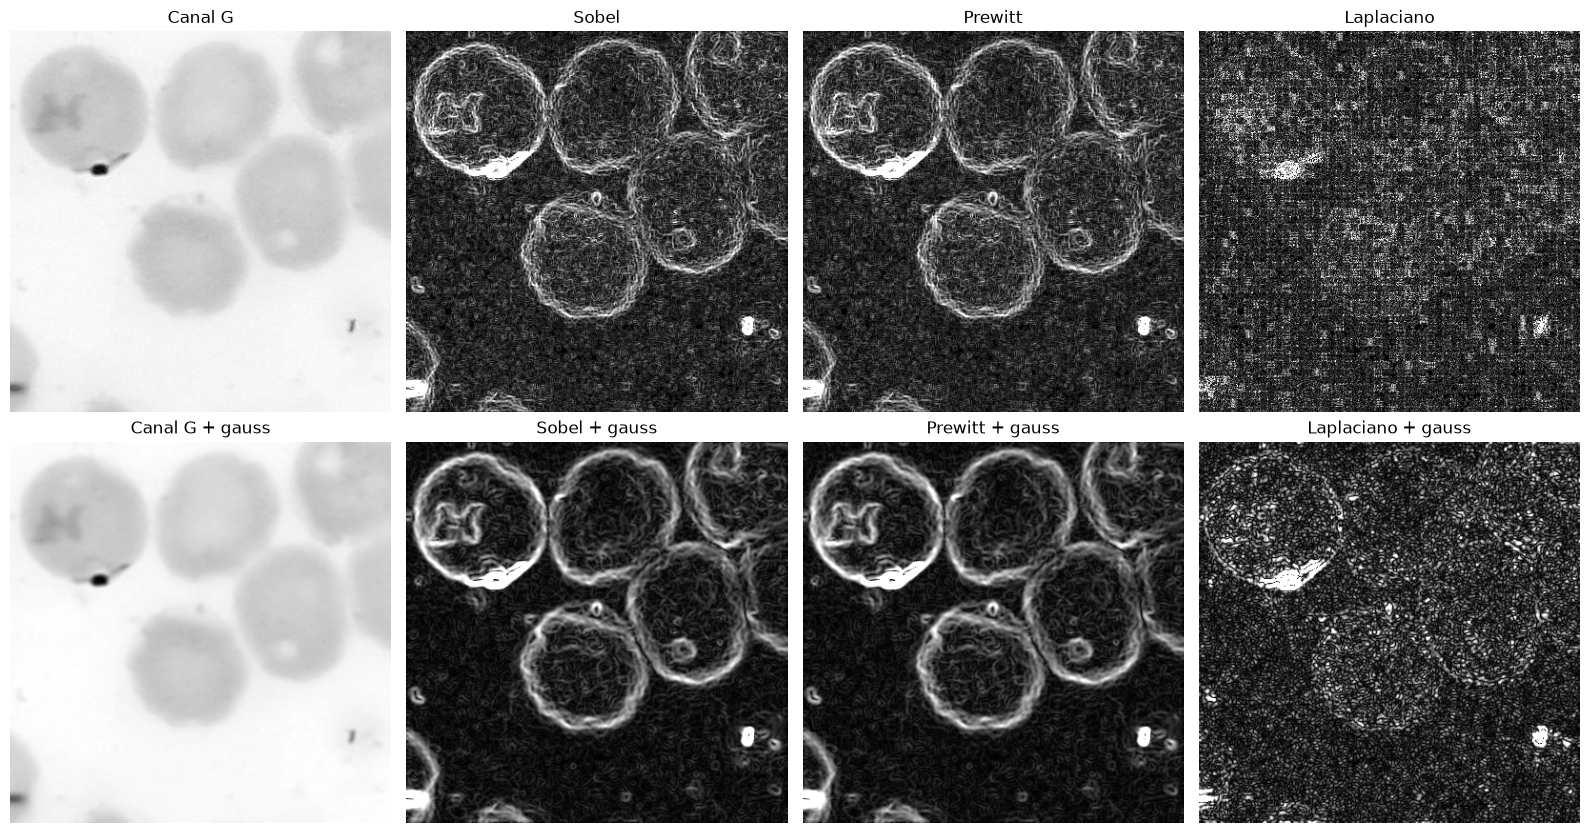

In [10]:
KERNEL_PREWITT_X = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float32)
KERNEL_PREWITT_Y = KERNEL_PREWITT_X.T


def filtro_bordes(canal, filtro, suavizar):
    # Respuesta de borde (siempre positiva) del filtro elegido sobre un canal
    img = canal.astype(np.float32)
    if suavizar:
        img = cv2.GaussianBlur(img, (5, 5), 1.5)
    if filtro == "Sobel":
        gx = cv2.Sobel(img, cv2.CV_32F, 1, 0, ksize=3)
        gy = cv2.Sobel(img, cv2.CV_32F, 0, 1, ksize=3)
        return np.sqrt(gx ** 2 + gy ** 2)
    if filtro == "Prewitt":
        gx = cv2.filter2D(img, cv2.CV_32F, KERNEL_PREWITT_X)
        gy = cv2.filter2D(img, cv2.CV_32F, KERNEL_PREWITT_Y)
        return np.sqrt(gx ** 2 + gy ** 2)
    return np.abs(cv2.Laplacian(img, cv2.CV_32F, ksize=1))  # Laplaciano con el núcleo 3x3 clásico


FILTROS = ["Sobel", "Prewitt", "Laplaciano"]
VARIANTES = [(f, s) for s in [False, True] for f in FILTROS]


def nombre_variante(filtro, suavizar):
    return f"{filtro} + gauss" if suavizar else filtro


# Recorte de ejemplo: centro de la primera imagen de train (como en la sección 2), normalizada por fondo
reg = imagenes[0]
img = normalizar(cargar_imagen(reg["patient_id"], reg["image_id"]), "Fondo", estadisticas[reg["image_id"]], referencia)
cy, cx = img.shape[0] // 2, img.shape[1] // 2
mitad = 200
zona = img[cy - mitad:cy + mitad, cx - mitad:cx + mitad]
verde = zona[:, :, 1]

fig, ax = plt.subplots(2, 4, figsize=(16, 8.5))
for fila, suavizar in enumerate([False, True]):
    ax[fila, 0].imshow(cv2.GaussianBlur(verde, (5, 5), 1.5) if suavizar else verde, cmap="gray")
    ax[fila, 0].set_title("Canal G" + (" + gauss" if suavizar else ""))
    for col, filtro in enumerate(FILTROS, start=1):
        respuesta = filtro_bordes(verde, filtro, suavizar)
        # Misma escala visual para todos: hasta el percentil 99 de cada respuesta
        ax[fila, col].imshow(respuesta, cmap="gray", vmin=0, vmax=np.percentile(respuesta, 99))
        ax[fila, col].set_title(nombre_variante(filtro, suavizar))
for a in ax.ravel():
    a.axis("off")
plt.tight_layout()
plt.show()

### Comparación cuantitativa con los contornos del GT

Para no elegir "a ojo", usamos los **polígonos del GT** como referencia de dónde están los bordes reales, en las 12 imágenes de train (normalizadas por fondo):
- **Borde:** una franja de 3 píxeles sobre el contorno de cada polígono.
- **Interior:** el interior de cada eritrocito, alejado 7 píxeles del contorno.
- **Fondo:** el fondo dentro del campo, alejado 7 píxeles de cualquier célula y 15 píxeles del borde del campo circular (que también es un borde muy fuerte).

Para cada filtro medimos:
- **AUC borde vs interior** y **AUC borde vs fondo**: qué tan bien la respuesta del filtro separa los píxeles de borde del resto. 1 = perfecto, 0.5 = no distingue. Como el AUC solo depende del orden de los valores, se pueden comparar filtros con escalas distintas.
- **Relación señal/fondo**: mediana de la respuesta en el borde dividida por la mediana en el fondo. Cuanto mayor, más "resalta" el contorno sobre el ruido del fondo.
- **Respuesta en el interior** de células **parasitadas** vs **sanas** (mediana del percentil 99 de cada célula): indica cuánto responde el filtro a las manchas del parásito. Es útil para textura (Bloque B), pero **molesta** para segmentar, porque genera bordes falsos dentro de las células.

In [11]:
N_BORDES = 20000  # píxeles por región y por imagen
SEP = 7           # separación (píxeles) entre el contorno y las zonas "interior" y "fondo"
rng_bordes = np.random.default_rng(SEED)

muestras = {nombre_variante(f, s): {"borde": [], "interior": [], "fondo": []} for f, s in VARIANTES}
p99_celulas = {nombre_variante(f, s): {LABEL_PARASITIZED: [], LABEL_UNINFECTED: []} for f, s in VARIANTES}

for reg in imagenes:
    img = normalizar(cargar_imagen(reg["patient_id"], reg["image_id"]), "Fondo", estadisticas[reg["image_id"]], referencia)
    verde = img[:, :, 1]
    anot, _ = cargar_gt(reg["patient_id"], reg["image_id"])
    polys = [np.round(a["polygon"]).astype(np.int32) for a in anot if a["polygon"] is not None]

    celulas_img = np.zeros(verde.shape, dtype=np.uint8)
    cv2.fillPoly(celulas_img, polys, 1)
    franja = np.zeros(verde.shape, dtype=np.uint8)
    cv2.polylines(franja, polys, True, 1, thickness=3)

    campo = cv2.erode(mascara_circular(img).astype(np.uint8), kernel_circular(15)) > 0
    interior = (cv2.erode(celulas_img, kernel_circular(SEP)) > 0) & campo
    fondo = (cv2.dilate(celulas_img, kernel_circular(SEP)) == 0) & campo
    borde = (franja > 0) & campo

    # Mismos píxeles para todos los filtros
    elegidos = {}
    for region, mascara in [("borde", borde), ("interior", interior), ("fondo", fondo)]:
        filas_px, cols_px = np.nonzero(mascara)
        k = rng_bordes.choice(len(filas_px), size=min(N_BORDES, len(filas_px)), replace=False)
        elegidos[region] = (filas_px[k], cols_px[k])

    for filtro, suavizar in VARIANTES:
        nombre = nombre_variante(filtro, suavizar)
        respuesta = filtro_bordes(verde, filtro, suavizar)
        for region, (f, c) in elegidos.items():
            muestras[nombre][region].append(respuesta[f, c])

        # Respuesta dentro de cada eritrocito (lejos del contorno): percentil 99
        for a in anot:
            if a["label"] not in [LABEL_PARASITIZED, LABEL_UNINFECTED] or a["polygon"] is None:
                continue
            poly = np.round(a["polygon"]).astype(np.int32)
            x0, y0 = np.maximum(poly.min(axis=0), 0)
            x1, y1 = poly.max(axis=0) + 1
            mascara = np.zeros((y1 - y0, x1 - x0), dtype=np.uint8)
            cv2.fillPoly(mascara, [poly - [x0, y0]], 1)
            dentro = cv2.erode(mascara, kernel_circular(SEP)) > 0
            if dentro.any():
                p99_celulas[nombre][a["label"]].append(np.percentile(respuesta[y0:y1, x0:x1][dentro], 99))

filas_bordes = []
for nombre, regiones in muestras.items():
    borde, interior, fondo = (np.concatenate(regiones[r]) for r in ["borde", "interior", "fondo"])
    auc_interior = roc_auc_score(np.r_[np.ones(len(borde)), np.zeros(len(interior))], np.r_[borde, interior])
    auc_fondo = roc_auc_score(np.r_[np.ones(len(borde)), np.zeros(len(fondo))], np.r_[borde, fondo])
    par = np.median(p99_celulas[nombre][LABEL_PARASITIZED])
    sana = np.median(p99_celulas[nombre][LABEL_UNINFECTED])
    filas_bordes.append({
        "filtro": nombre,
        "AUC borde vs interior": auc_interior,
        "AUC borde vs fondo": auc_fondo,
        "señal/fondo (medianas)": np.median(borde) / np.median(fondo),
        "interior parasitada / sana (p99)": par / sana,
    })

comparacion_bordes = pd.DataFrame(filas_bordes).set_index("filtro")
comparacion_bordes.round(3)

,AUC borde vs interior,AUC borde vs fondo,señal/fondo (medianas),interior parasitada / sana (p99)
filtro,,,,
Sobel,0.764,0.879,3.138,5.385
Prewitt,0.769,0.884,3.340,5.503
Laplaciano,0.503,0.584,1.000,1.800
Sobel + gauss,0.845,0.948,7.318,6.640
Prewitt + gauss,0.845,0.949,7.413,6.623
Laplaciano + gauss,0.576,0.666,1.797,5.014


Distribución de la respuesta de cada filtro en las tres regiones (con suavizado gaussiano). En el eje Y, la frecuencia relativa de cada región; el eje X está cortado en el percentil 99 para que se vea la forma.

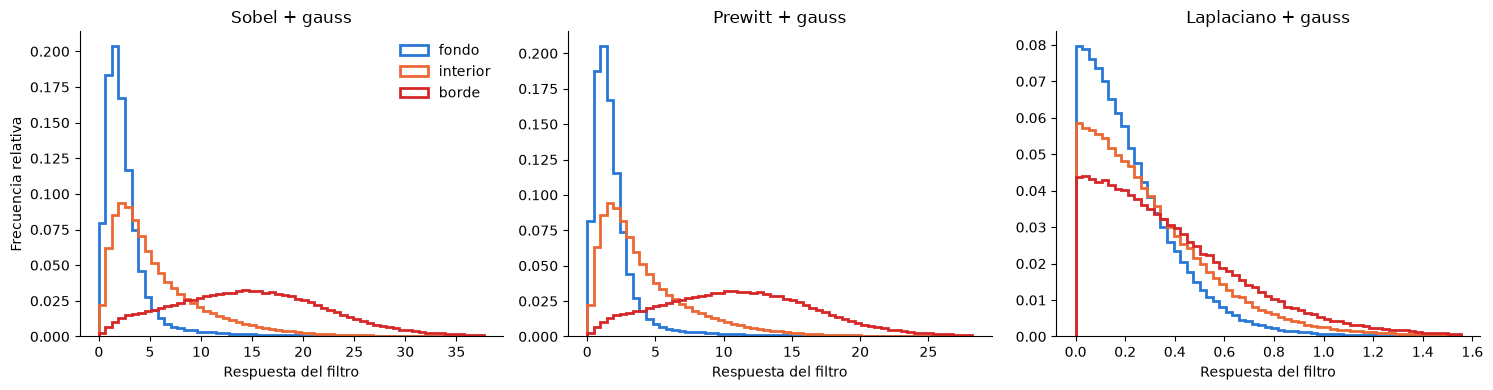

In [12]:
COLOR_REGION = {"borde": "#d62728", "interior": "#eb6834", "fondo": "#2a78d6"}

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for eje, filtro in zip(ax, FILTROS):
    nombre = nombre_variante(filtro, True)
    todos = np.concatenate([np.concatenate(v) for v in muestras[nombre].values()])
    bins = np.linspace(0, np.percentile(todos, 99), 60)
    for region in ["fondo", "interior", "borde"]:
        valores = np.concatenate(muestras[nombre][region])
        pesos = np.ones(len(valores)) / len(valores)  # frecuencia relativa: cada región suma 1
        eje.hist(valores, bins=bins, weights=pesos, histtype="step", linewidth=2, color=COLOR_REGION[region], label=region)
    eje.set_title(nombre)
    eje.set_xlabel("Respuesta del filtro")
    eje.spines[["top", "right"]].set_visible(False)
ax[0].set_ylabel("Frecuencia relativa")
ax[0].legend(frameon=False)
plt.tight_layout()
plt.show()

**Qué se ve:**
- **Sobel y Prewitt son prácticamente equivalentes** (AUC borde vs fondo 0.88 sin suavizar y 0.95 con gaussiano, en los dos). Prewitt queda apenas arriba, pero la diferencia es despreciable.
- **El suavizado gaussiano previo ayuda mucho** a los tres filtros: con Sobel, el AUC borde vs fondo sube de 0.88 a 0.95 y la relación señal/fondo pasa de ≈3 a ≈7. Sin suavizar, el ruido del fondo y del interior genera muchos "bordes" falsos (se ve como textura granulada en la figura).
- **El valor absoluto del Laplaciano rinde mal con esta métrica** (AUC 0.58 sin suavizar, 0.67 con gaussiano). Hay dos razones:
  - Es una **segunda derivada**: amplifica mucho más el ruido. Sin suavizar, en la figura se ve incluso la **grilla de bloques de 8×8 de la compresión JPEG**.
  - En el centro de un borde la segunda derivada **cruza por cero**: el borde aparece como un cambio de signo, no como un máximo. Por eso su valor absoluto sobre el contorno es bajo, y esta medición lo perjudica. Para usarlo como detector de bordes habría que buscar los **cruces por cero**, no el valor absoluto.
- **Todos los filtros responden fuerte a los parásitos** (el p99 dentro de las parasitadas es 5-7 veces el de las sanas). En la figura, el parásito y el borde de la célula aparecen igual de brillantes. Esto es **malo para segmentar** (bordes falsos dentro de la célula) pero **útil para textura**: indica variaciones locales de intensidad que también pueden caracterizarse mediante la GLCM del Bloque B.
- El AUC **borde vs interior** es siempre más bajo que **borde vs fondo**: el interior de los eritrocitos tiene más variación (la palidez central, las manchas) que el fondo.

> Nota: la franja de "borde" sale de los polígonos dibujados a mano, que no siempre coinciden exactamente con el borde real (pueden estar corridos 1-2 píxeles). Eso baja todos los AUC por igual, así que no cambia la comparación entre filtros.

## 8. Conclusiones de C2

### Normalización

1. **La variación de color entre imágenes de train es chica** y podría estar asociada principalmente a diferencias de tinción entre preparados más que a la iluminación (no medimos esas causas por separado). El balance de blancos deja el fondo igual en todas, pero casi no cambia el color de las células.
2. **Para segmentar (fondo vs células) no hace falta normalizar:** Otsu ya se adapta a cada imagen.
3. **Para el canal b (lo violeta) la normalización sí ayuda**, porque es el canal más sensible al tono de la tinción. Esto sirve para excluir glóbulos blancos (A) y para la máscara violeta de C3.
4. **Recomendación:** usar la **normalización por fondo (balance de blancos)** como alternativa inicial para el Bloque C, por su simplicidad y porque conserva visualmente las características de la tinción. No necesita etiquetas del GT y depende **mucho menos del contenido de la imagen** que Reinhard: solo usa el fondo, aunque como lo estima con Otsu, la cantidad de células puede moverlo un poco. En la validación por paciente con referencia independiente (sección 6) mejora la exactitud balanceada para distinguir WBC de eritrocitos de **0.820 a 0.849**. **Reinhard** alcanza 0.884 en esa comparación y 0.699 con `b_p5`, pero depende de la media y el desvío de toda la imagen (o sea, de cuántas células y parásitos tiene) y aumenta la variación en G y L. Se conserva como alternativa para evaluar en C5.
5. **La normalización no resuelve la detección de parasitadas.** Con un solo umbral por célula, en un paciente nuevo la exactitud balanceada es baja y varía mucho entre pacientes. Esto refuerza que hace falta combinar varias características (proporción de píxeles oscuros/violetas en C4, textura GLCM del Bloque B) y no un único canal.
6. Para evaluar en C5 conviene usar **validación por paciente** en train, porque juntar pacientes sobreestima el rendimiento.
7. Excluir al paciente evaluado del cálculo de la referencia (sección 6) produjo **cambios pequeños en la mayoría de las métricas promedio**, aunque en algunos pacientes las diferencias individuales fueron mayores (hasta ≈0.1, en pacientes con 4-5 parasitadas). La interpretación general se mantuvo, y en las evaluaciones posteriores se usa una referencia calculada **solo con los pacientes de entrenamiento** de cada partición (así se hizo en la validación anidada de C3).

**Para aplicar a test:** se calculan las estadísticas de cada imagen de test (sin GT) y se normaliza con la **referencia de train** (`referencia`), sin recalcularla.

### Filtros de bordes

8. **Sobel y Prewitt** son los mejores para resaltar el contorno de los eritrocitos y dan resultados casi idénticos. Conviene aplicarlos **después de un suavizado gaussiano**: el AUC borde vs fondo sube de 0.88 a 0.95 y la relación señal/fondo se duplica.
9. **El valor absoluto del Laplaciano** obtuvo resultados mucho peores con la métrica usada: amplifica el ruido (incluso los bloques de la compresión JPEG) y marca el borde como un **cruce por cero**, no como un máximo. Con suavizado (LoG) mejora, pero sigue muy por debajo de Sobel y Prewitt. Esto no descarta el Laplaciano en general: para usarlo como detector de bordes habría que estudiar sus **cruces por cero**, que acá no evaluamos.
10. **Recomendación para el Bloque A:** usar **Sobel sobre G suavizado** (o Prewitt, es indistinto) como información complementaria de bordes, por ejemplo para refinar el contorno de las células en la segmentación dirigida (A6) o como imagen de gradiente para Watershed. Hay que tener en cuenta que el filtro también responde fuerte a los parásitos, así que no sirve solo para separar células: dentro de una célula parasitada aparecen bordes internos.
11. Esa respuesta a los parásitos (5-7 veces mayor que en células sanas) es coherente con la presencia de **variaciones locales de intensidad** dentro de las células parasitadas, que también pueden caracterizarse mediante la GLCM del Bloque B.